# Data report: numbers for Milestone 1 (Section 2.3 and 2.4)

Computes the numbers in Sections 2.3 and 2.4 of the Milestone 1 report from the files in `data/`.

**Part A – National dataset** (Google News front page and search check), in report order:
1. the analysis sample;
2. missingness summary;
3. summary stats;
4. duplicates and outliers;
5. example rows (Table 1);
6. plots (Figures 3 and 4).

**Part B – Local dataset** (Google News Local pages and Ontario towns): missingness, issues and example rows (Table 2). The town-size shares (Figure 1) and acclaimed mayors (Figure 2) come from sections 1 and 6 of `main_findings.ipynb`.

Every national number is also stored in a table, saved to `outputs/national_report_stats.csv` with the report section it belongs to. Figures are saved to `outputs/`.

Run the cells top to bottom from the repository root or from any subfolder.

In [18]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'google_news_front_page').exists())
FP, SC, OUT = ROOT / 'data' / 'google_news_front_page', ROOT / 'data' / 'search_check', ROOT / 'outputs'
OUT.mkdir(exist_ok=True)

snaps = pd.read_csv(FP / 'snapshots.csv', dtype={'timestamp': str})
art = pd.read_csv(FP / 'front_page_articles.csv', dtype={'timestamp': str}, low_memory=False)
outlets = pd.read_csv(FP / 'outlets.csv')
results = pd.read_csv(SC / 'search_results.csv')
search_stories = pd.read_csv(SC / 'search_stories.csv')

STATS = []
def record(section, name, value):
    STATS.append({'report_section': section, 'statistic': name, 'value': value})
    print(f'{name}: {value}')

pct = lambda x: round(100 * float(x), 1)

# Part A – National dataset

## 1. The analysis sample

Same filter as `main_findings.ipynb`: snapshots drawn for the analysis (`purpose == 'main'`), downloaded, and not excluded (the Archive served a page more than 3 h from the requested time).

`front_page_articles.csv` also holds rows from pages that are not in this sample: the same-day repeats, the excluded snapshots, and 67 cached pages that are not listed in `snapshots.csv` (`01_front_page.ipynb` parses every page in `cache/`). Those rows are left out of every number below.

In [19]:
bool_col = lambda s: s.astype(str).eq('True')
use = snaps[snaps.purpose.eq('main') & bool_col(snaps.downloaded) & ~bool_col(snaps.exclude)]

record('2.3 missingness', 'snapshots drawn', len(snaps))
record('2.3 missingness', 'snapshots not downloaded', int((~bool_col(snaps.downloaded)).sum()))
record('2.3 missingness', 'snapshots excluded (wrong date served)', int(bool_col(snaps.exclude).sum()))
record('2.3 missingness', 'same-day repeat snapshots', int(snaps.purpose.eq('repeat').sum()))
record('2.3 missingness', 'analysis sample: snapshots', len(use))
record('2.3 missingness', 'analysis sample: English snapshots', int(use.edition.eq('en-CA').sum()))
record('2.3 missingness', 'analysis sample: French snapshots', int(use.edition.eq('fr-CA').sum()))

not_listed = set(art.timestamp) - set(snaps.timestamp)
record('2.3 duplicates', 'pages in articles file not listed in snapshots.csv', len(not_listed))
record('2.3 duplicates', 'article rows from those pages', int(art.timestamp.isin(not_listed).sum()))
record('2.3 duplicates', 'article rows from repeat snapshots', int(art.timestamp.isin(snaps[snaps.purpose.eq('repeat')].timestamp).sum()))
record('2.3 duplicates', 'article rows from excluded snapshots', int(art.timestamp.isin(snaps[bool_col(snaps.exclude)].timestamp).sum()))

a = art[art.timestamp.isin(use.timestamp)].copy()
a['group'] = a.group.fillna('unknown')
a['captured'] = pd.to_datetime(a.timestamp, format='%Y%m%d%H%M%S')
record('2.3 summary', 'analysis sample: article rows', len(a))

snapshots drawn: 1480
snapshots not downloaded: 6
snapshots excluded (wrong date served): 5
same-day repeat snapshots: 133
analysis sample: snapshots: 1336
analysis sample: English snapshots: 723
analysis sample: French snapshots: 613
pages in articles file not listed in snapshots.csv: 67
article rows from those pages: 827
article rows from repeat snapshots: 1642
article rows from excluded snapshots: 65
analysis sample: article rows: 16378


## 2. Missingness summary

In [20]:
# Months with no snapshot, and months with few French snapshots
months = pd.period_range('2022-05', '2026-10', freq='M')
per_month = (use.assign(month=pd.to_datetime(use.timestamp.str[:6], format='%Y%m').dt.to_period('M'))
                .groupby(['month', 'edition']).size().unstack(fill_value=0).reindex(months, fill_value=0))
for ed in ['en-CA', 'fr-CA']:
    record('2.3 missingness', f'{ed}: months with no snapshot', ', '.join(str(m) for m in per_month.index[per_month[ed] == 0]))
low_fr = per_month[(per_month['fr-CA'] > 0) & (per_month['fr-CA'] < 8)]['fr-CA']
record('2.3 missingness', 'fr-CA: months with 1-7 snapshots', ', '.join(f'{m} ({n})' for m, n in low_fr.items()))

en-CA: months with no snapshot: 2022-06, 2022-07, 2022-08, 2022-09
fr-CA: months with no snapshot: 2022-06, 2022-07, 2022-08, 2022-09, 2023-09, 2026-06
fr-CA: months with 1-7 snapshots: 2022-05 (4), 2022-10 (4), 2023-02 (4), 2025-09 (7), 2026-07 (4), 2026-08 (4), 2026-09 (6), 2026-10 (5)


In [21]:
# Empty values per column of the article table (analysis sample)
print((a.isna().mean() * 100).round(1)[lambda s: s > 0].rename('% empty').to_string(), '\n')

record('2.3 missingness', '% of article rows with empty story_id', pct(a.story_id.isna().mean()))
for year, share in a.story_id.isna().groupby(a.timestamp.str[:4]).mean().items():
    record('2.3 missingness', f'% empty story_id in {year}', pct(share))
record('2.3 missingness', '% of article rows with empty cjc_sub / payee_legal (no CJC payment)', pct(a.payee_legal.isna().mean()))

record('2.3 missingness', 'outlets in outlets.csv', len(outlets))
record('2.3 missingness', '% of outlets with no CJC payee match', pct(outlets.payee_legal.isna().mean()))
record('2.3 missingness', 'outlets in group unknown', int(outlets.group.eq('unknown').sum()))

record('2.3 missingness', 'search check: % of results with empty published', pct(results.published.isna().mean()))
record('2.3 missingness', 'search check: stories with empty major_time', int(search_stories.major_time.isna().sum()))

story_id          47.2
publisher          0.1
publication_id     0.7
cjc_sub           20.9
payee_legal       20.9 

% of article rows with empty story_id: 47.2
% empty story_id in 2022: 59.4
% empty story_id in 2023: 54.1
% empty story_id in 2024: 46.1
% empty story_id in 2025: 42.7
% empty story_id in 2026: 42.6
% of article rows with empty cjc_sub / payee_legal (no CJC payment): 20.9
outlets in outlets.csv: 654
% of outlets with no CJC payee match: 64.4
outlets in group unknown: 157
search check: % of results with empty published: 50.5
search check: stories with empty major_time: 12


## 3. Summary stats for important numeric fields

In [22]:
# Rows per edition and section, articles per page
print(a.groupby(['edition', 'section']).size().to_string(), '\n')
for (ed, sec), n in a.groupby(['edition', 'section']).size().items():
    record('2.3 summary', f'rows: {ed} / {sec}', int(n))
per_page = a.groupby('timestamp').size()
record('2.3 summary', 'articles per page: mean', round(per_page.mean(), 1))
record('2.3 summary', 'articles per page: min', int(per_page.min()))
record('2.3 summary', 'articles per page: max', int(per_page.max()))

# Cluster size: 1 = single-article card, 3-4 = story cluster
print(a.cluster_size.value_counts().sort_index().to_string(), '\n')
record('2.3 summary', 'rows in single-article cards (cluster_size 1)', int(a.cluster_size.eq(1).sum()))
record('2.3 summary', 'rows in story clusters (cluster_size 3-4)', int(a.cluster_size.ge(2).sum()))
record('2.3 summary', 'largest cluster_size', int(a.cluster_size.max()))

edition  section             
en-CA    Picks for you           2165
         Top stories             7029
fr-CA    Sélections pour vous    1831
         À la une                5353 

rows: en-CA / Picks for you: 2165
rows: en-CA / Top stories: 7029
rows: fr-CA / Sélections pour vous: 1831
rows: fr-CA / À la une: 5353
articles per page: mean: 12.3
articles per page: min: 6
articles per page: max: 14
cluster_size
1    7732
3     198
4    8448 

rows in single-article cards (cluster_size 1): 7732
rows in story clusters (cluster_size 3-4): 8646
largest cluster_size: 4


In [23]:
# Article age when the page was captured, in hours
a['age_h'] = ((a.captured - pd.Timestamp('1970-01-01')).dt.total_seconds() - a.published_unix) / 3600
print(a.age_h.describe(percentiles=[.5, .9, .99]).round(1).to_string(), '\n')
record('2.3 summary', 'article age: median (h)', round(a.age_h.median(), 1))
record('2.3 summary', 'article age: 90th percentile (h)', round(a.age_h.quantile(.9), 1))

count    16378.0
mean        15.7
std        518.2
min         -1.4
50%          6.9
90%         24.5
99%         60.2
max      65915.3 

article age: median (h): 6.9
article age: 90th percentile (h): 24.5


In [24]:
# How concentrated exposure is across outlets (slots per outlet in the sample)
slots = a.groupby('outlet').size().sort_values(ascending=False)
print(slots.head(10).to_string(), '\n')
record('2.3 summary', 'outlets in the sample', len(slots))
record('2.3 summary', '% of slots held by the top 10 outlets', pct(slots.head(10).sum() / slots.sum()))
record('2.3 summary', 'slots of the median outlet', float(slots.median()))
for outlet, n in slots.head(3).items():
    record('2.3 summary', f'slots: {outlet}', int(n))

outlet
lapresse.ca              1427
journaldemontreal.com    1387
cbc.ca                   1358
tvanouvelles.ca          1217
ici.radio-canada.ca       994
ctvnews.ca                926
journaldequebec.com       720
theglobeandmail.com       618
globalnews.ca             610
ledevoir.com              422 

outlets in the sample: 611
% of slots held by the top 10 outlets: 59.1
slots of the median outlet: 2.0
slots: lapresse.ca: 1427
slots: journaldemontreal.com: 1387
slots: cbc.ca: 1358


In [25]:
# Share of all slots and of lead slots (slot 0) by outlet group
lead = a[a.slot.eq(0)]
shares = pd.DataFrame({'% of all slots': (a.group.value_counts(normalize=True) * 100).round(1),
                       '% of lead slots': (lead.group.value_counts(normalize=True) * 100).round(1)})
print(shares.to_string(), '\n')
record('2.3 summary', 'lead slots (slot 0)', len(lead))
for g, row in shares.iterrows():
    record('2.3 summary', f'{g}: % of all slots', row['% of all slots'])
    record('2.3 summary', f'{g}: % of lead slots', row['% of lead slots'])
SMALL = ['local_en', 'franco', 'diaspora']   # smaller paid outlets, as in main_findings.ipynb
record('2.4 class imbalance', 'smaller paid outlets: % of lead slots', pct(lead.group.isin(SMALL).mean()))

            % of all slots  % of lead slots
group                                      
cdn_unpaid             2.1              1.7
foreign               17.7             14.9
franco                 3.7              1.6
local_en               2.1              2.2
major                 73.4             78.6
unknown                1.1              0.9 

lead slots (slot 0): 9910
cdn_unpaid: % of all slots: 2.1
cdn_unpaid: % of lead slots: 1.7
foreign: % of all slots: 17.7
foreign: % of lead slots: 14.9
franco: % of all slots: 3.7
franco: % of lead slots: 1.6
local_en: % of all slots: 2.1
local_en: % of lead slots: 2.2
major: % of all slots: 73.4
major: % of lead slots: 78.6
unknown: % of all slots: 1.1
unknown: % of lead slots: 0.9
smaller paid outlets: % of lead slots: 3.9


In [26]:
# Search check: on-story share, mean rank, which group holds the top result
record('2.3 summary', 'search check: results', len(results))
record('2.3 summary', 'search check: % of results about the right story', pct(results.on_story.mean()))
on = results[results.on_story.astype(str).eq('True')]
print(on.groupby(['engine', 'size_group'])['rank'].agg(['count', 'mean']).round(1).to_string(), '\n')
for (eng, grp), r in on.groupby(['engine', 'size_group'])['rank'].mean().items():
    record('2.3 summary', f'search check: mean rank, {eng} / {grp}', round(r, 1))
top = on.sort_values('rank').groupby(['story_id', 'engine']).first()
for (eng, grp), n in top.groupby('engine').size_group.value_counts().items():
    record('2.3 summary', f'search check: stories where top result is {grp} ({eng})', int(n))

search check: results: 487
search check: % of results about the right story: 84.6
                    count  mean
engine  size_group             
gnews   major         125   4.4
        other          26   6.0
        small          53   4.7
gsearch major         122   4.4
        other          32   5.7
        small          54   4.8 

search check: mean rank, gnews / major: 4.4
search check: mean rank, gnews / other: 6.0
search check: mean rank, gnews / small: 4.7
search check: mean rank, gsearch / major: 4.4
search check: mean rank, gsearch / other: 5.7
search check: mean rank, gsearch / small: 4.8
search check: stories where top result is major (gnews): 24
search check: stories where top result is small (gnews): 6
search check: stories where top result is other (gnews): 1
search check: stories where top result is major (gsearch): 22
search check: stories where top result is small (gsearch): 7
search check: stories where top result is other (gsearch): 2


## 4. Duplicates and outliers

In [27]:
record('2.3 duplicates', 'same link twice on one page', int(a.duplicated(['timestamp', 'url']).sum()))
record('2.3 duplicates', 'same headline twice on one page', int(a.duplicated(['timestamp', 'headline']).sum()))

record('2.3 outliers', 'articles published after the capture time', int((a.age_h < -0.1).sum()))   # 0.1 h tolerance
record('2.3 outliers', 'largest negative age (h)', round(a.age_h.min(), 1))
record('2.3 outliers', 'articles more than 7 days old when captured', int((a.age_h > 168).sum()))
record('2.3 outliers', 'oldest article (years)', round(a.age_h.max() / (24 * 365.25), 1))
print()
print(a.nsmallest(3, 'age_h')[['timestamp', 'outlet', 'headline', 'age_h']].to_string())
print(a.nlargest(3, 'age_h')[['timestamp', 'outlet', 'headline', 'age_h']].to_string())

same link twice on one page: 0
same headline twice on one page: 1
articles published after the capture time: 7
largest negative age (h): -1.4
articles more than 7 days old when captured: 33
oldest article (years): 7.5

            timestamp             outlet                                                                                     headline     age_h
14188  20250927225852  independent.co.uk  Portlanders mock Trump by posting pics of peaceful weekend activities in ‘War ravaged’ city -1.402222
14187  20250927225852             cbc.ca       Oregon officials, residents slam 'ridiculous' Trump order to send troops into Portland -0.727222
14089  20250919171546         ctvnews.ca                                      Liberals’ new hate crime bill targets ‘symbols’ of hate -0.611389
           timestamp              outlet                                                                                      headline         age_h
7055  20240415181715  washingtonpost.com                

## 5. Example rows (Table 1)

In [28]:
cols = ['timestamp', 'edition', 'section', 'card', 'slot', 'cluster_size', 'headline', 'outlet', 'group', 'cjc_y2']
example = pd.concat([a[a.timestamp.eq('20260117022450') & a.card.eq(1)].head(3),
                     a[a.timestamp.eq('20260522004240') & a.card.eq(0) & a.slot.eq(0)]])[cols]
example

,timestamp,edition,section,card,slot,cluster_size,headline,outlet,group,cjc_y2
15762,20260117022450,en-CA,Top stories,1,0,4,Blair and Rubio among names on Gaza 'Board of ...,bbc.com,foreign,0.00
15763,20260117022450,en-CA,Top stories,1,1,4,Carney to accept Trump’s offer for role on Gaz...,ctvnews.ca,major,8646776.15
15764,20260117022450,en-CA,Top stories,1,2,4,CP NewsAlert: Carney to join Trump’s ‘Board of...,panow.com,local_en,584853.84
17524,20260522004240,fr-CA,À la une,0,0,4,Des Canadiens iront aider la République démocr...,granbyexpress.com,franco,931762.35
17534,20260522004240,fr-CA,Sélections pour vous,0,0,1,Il aurait drogué une femme dans un bar pour l’...,journaldemontreal.com,major,2398347.94


## 6. Plots (Figures 3 and 4)

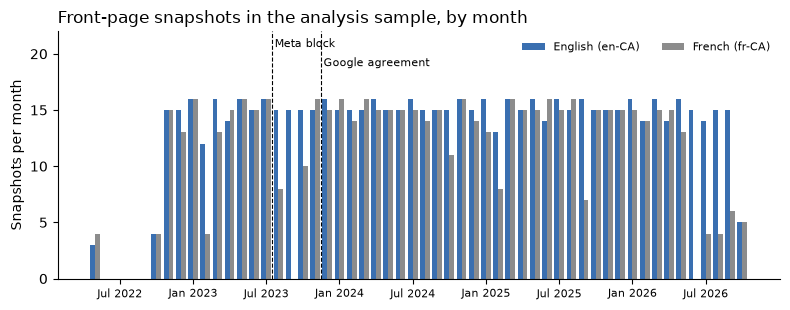

In [29]:
BLUE, GREY = '#3a6fb0', '#8c8c8c'

# Figure 3: snapshots per month and edition
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(months))
ax.bar(x - .2, per_month['en-CA'], width=.4, color=BLUE, label='English (en-CA)')
ax.bar(x + .2, per_month['fr-CA'], width=.4, color=GREY, label='French (fr-CA)')
ticks = [i for i, m in enumerate(months) if m.month in (1, 7)]
ax.set_xticks(ticks, [months[i].strftime('%b %Y') for i in ticks], fontsize=8)
for month, label, y in [('2023-08', 'Meta block', 20.6), ('2023-12', 'Google agreement', 18.9)]:
    i = list(months).index(pd.Period(month, 'M'))
    ax.axvline(i - .5, ls='--', color='black', lw=.8); ax.text(i - .3, y, label, fontsize=8)
ax.set_ylabel('Snapshots per month'); ax.set_ylim(0, 22)
ax.legend(fontsize=8, loc='upper right', ncol=2, frameon=False)
ax.set_title('Front-page snapshots in the analysis sample, by month', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); fig.savefig(OUT / 'fig3_snapshots_per_month.png', dpi=200); plt.show()

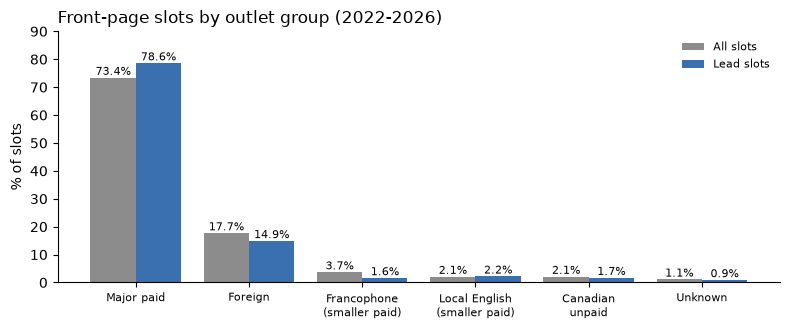

In [30]:
# Figure 4: share of all slots vs lead slots by outlet group
order = ['major', 'foreign', 'franco', 'local_en', 'cdn_unpaid', 'unknown']
names = ['Major paid', 'Foreign', 'Francophone\n(smaller paid)', 'Local English\n(smaller paid)', 'Canadian\nunpaid', 'Unknown']
s = shares.reindex(order).fillna(0)
fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(order))
for offset, col, color in [(-.2, '% of all slots', GREY), (.2, '% of lead slots', BLUE)]:
    bars = ax.bar(x + offset, s[col], width=.4, color=color, label=col.replace('% of ', '').capitalize())
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f'{b.get_height():.1f}%', ha='center', fontsize=8)
ax.set_xticks(x, names, fontsize=8); ax.set_ylabel('% of slots'); ax.set_ylim(0, 90)
ax.legend(fontsize=8, frameon=False)
ax.set_title('Front-page slots by outlet group (2022-2026)', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); fig.savefig(OUT / 'fig4_slots_by_group.png', dpi=200); plt.show()

## Save all national numbers

In [31]:
stats = pd.DataFrame(STATS)
stats.to_csv(OUT / 'national_report_stats.csv', index=False)
print(f'{len(stats)} numbers saved to outputs/national_report_stats.csv')
stats

79 numbers saved to outputs/national_report_stats.csv


,report_section,statistic,value
0,2.3 missingness,snapshots drawn,1480
1,2.3 missingness,snapshots not downloaded,6
2,2.3 missingness,snapshots excluded (wrong date served),5
3,2.3 missingness,same-day repeat snapshots,133
4,2.3 missingness,analysis sample: snapshots,1336
...,...,...,...
74,2.3 duplicates,same headline twice on one page,1
75,2.3 outliers,articles published after the capture time,7
76,2.3 outliers,largest negative age (h),-1.4
77,2.3 outliers,articles more than 7 days old when captured,33


# Part B – Local dataset

Missing values in every local table are saved to `outputs/local_missingness.csv`; the cells below give the numbers used in Sections 2.3 and 2.4.

In [32]:
LP = ROOT / 'data' / 'google_news_local_pages'
TW = ROOT / 'data' / 'ontario_towns'

tables = {'local_page_cards': pd.read_csv(LP / 'local_page_cards.csv', low_memory=False),
          'repeat_readings': pd.read_csv(LP / 'local_page_cards_repeat_readings.csv'),
          'local_page_by_town': pd.read_csv(LP / 'local_page_by_town.csv'),
          'towns': pd.read_csv(TW / 'towns.csv'),
          'races_2026': pd.read_csv(TW / 'races_2026.csv'),
          'local_outlets': pd.read_csv(TW / 'local_outlets.csv', low_memory=False),
          'local_stories': pd.read_csv(TW / 'local_stories.csv', low_memory=False),
          'civic_outcomes': pd.read_csv(TW / 'civic_outcomes.csv')}
all_cards, rep, bytown, stories, civ = (tables[k] for k in
    ['local_page_cards', 'repeat_readings', 'local_page_by_town', 'local_stories', 'civic_outcomes'])

# missing values: every column with any, saved for the report
miss = pd.concat([pd.DataFrame({'table': n, 'column': d.columns, 'n_missing': d.isna().sum().values,
                                'pct_missing': (d.isna().mean() * 100).round(1).values}) for n, d in tables.items()])
miss = miss[miss.n_missing > 0]
miss.to_csv(OUT / 'local_missingness.csv', index=False)
miss

,table,column,n_missing,pct_missing
16,local_page_cards,other_town_race,20650,96.2
5,local_page_by_town,french_mt_share,1,0.3
6,local_page_by_town,franco_band,1,0.3
7,local_page_by_town,stratum,394,100.0
9,local_page_by_town,probe_headline,394,100.0
...,...,...,...,...
6,local_stories,title,585,1.0
7,local_stories,title_clean,585,1.0
8,local_stories,title_norm,1225,2.1
14,local_stories,home_veto,58088,98.9


In [33]:
read = bytown[bytown.outcome != 'not_collected']   # the towns that were read
days = set(pd.to_datetime(pd.concat([all_cards.run, rep.run]), format='%Y%m%dT%H%MZ').dt.date)

print('Towns not collected:', (bytown.outcome == 'not_collected').sum(), 'of', len(bytown))
print('Empty columns (to drop):', [c for c in bytown.columns if bytown[c].isna().all()])
print('Towns read with 0 French cards:', (read['cards_fr-CA'] == 0).sum(), 'of', len(read))
print('Turnout missing:', civ.turnout_2022.isna().sum(), '| all with a fully acclaimed council:',
      civ.loc[civ.turnout_2022.isna(), 'council_fully_acclaimed_2022'].all())
print('Days with no reading (Oct 12-16):', [str(d) for d in pd.date_range('2026-10-12', '2026-10-16').date if d not in days])
print('Election cards about the town:', int(all_cards.race_card.sum()), 'of', len(all_cards),
      '| towns read under 10,000:', (read.population_2021 < 10000).sum(), 'of', len(read))
print('Same link twice on a page:', all_cards.duplicated(['town_id', 'edition', 'link']).sum(),
      '| syndicated titles per town:', stories.duplicated(['title_norm', 'town_id']).sum(),
      '| most stories for one town:', stories.groupby('town_id').size().max())

Towns not collected: 4 of 394
Empty columns (to drop): ['stratum', 'probe_headline', 'probe_shown', 'web_recall_tiers']
Towns read with 0 French cards: 256 of 390
Turnout missing: 32 | all with a fully acclaimed council: True
Days with no reading (Oct 12-16): ['2026-10-14', '2026-10-15', '2026-10-16']
Election cards about the town: 360 of 21461 | towns read under 10,000: 239 of 390
Same link twice on a page: 13 | syndicated titles per town: 11533 | most stories for one town: 18397


In [34]:
# example rows (Table 2): two cards about the town's own race, one about another town's race
cols = ['town_id', 'edition', 'rank', 'headline', 'source', 'time', 'race_card', 'other_town_race']
pd.concat([all_cards[all_cards.race_card].head(2), all_cards[all_cards.other_town_race.notna()].head(1)])[cols]

,town_id,edition,rank,headline,source,time,race_card,other_town_race
349,3502044,fr-CA,16,Un conseiller de Casselman veut faire le saut ...,Le Droit,2026-01-18T08:00:00Z,True,NaN
573,3511005,en-CA,59,"Six questions with Paul Proderick, candidate f...",Kingstonist News,2026-09-24T07:00:00Z,True,NaN
1,3501005,en-CA,2,Homelessness the top issue at Cornwall mayoral...,Cornwall Standard Freeholder,2026-10-09T20:44:03Z,False,3501012
